# Train a neural network rocket controller

This is a very basic training script for the model.py. Use this to train and evaluate your model before uploading it to the online sandbox.

Some suggestions for model training improvements:
- Sampling some stages of flights more than others may allow your model to learn more about the more important regions
- Filtering by only successful flights
- Changing the learning rate, epochs and batch size
- Changing the loss function (the idea behind a good loss function is to represent the scoring of your problem well -> MSE may not be optimal)
- More layers
- Wider layers
- Create features in the model before you pass them through the network -> for example you could square all the inputs and then pass them into your model
- You may use different layer types, however I do not recommend just blindly applying them
- Look at the plot of training loss vs validation loss - you may overfit or underfit
- Different activation functions may perform better

If it takes a long time to train:
- use CUDA or MPS if you have an available GPU
- reduce the number of epochs and increase the learning rate
- reduce the number of model parameters
- do not use numpy etc in your model if you are running on a GPU -> the swaps will slow down the model substantially
- use a smaller dataset

In [77]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [78]:
# Import anything you like, but expect the sandbox to only have the following packages installed:
import importlib
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from model import FEATURES, TARGETS, create_model
from safetensors.torch import load_file, save_file
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

In [79]:

# Do not change this unless you have renamed the file.
landings_path = Path("landings.csv")
# The seed makes runs reproducible. You can change this to any integer you like.
# If you do not set this it makes it difficult to determine whether improvements are noise or due to model changes.
seed = 42
np.random.seed(seed)
torch.manual_seed(seed)
# A higher learning rate will make the model converge faster but it also may diverge/be unstable.
# With a lower learning rate you will need more epochs but you also may sit in a local minimum
# instead of finding a better solution.
learning_rate = 0.001
# Just the number of passes through your training dataset.
# You can increase this if you see that the model is still improving at the end of training.
epochs = 30
# The number of samples it processes at once.
# A higher batch size will make the model converge faster but it also may diverge/be unstable.
# With a lower batch size you will need more epochs but you also may sit in a local minimum.
batch_size = 256

device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")

In [80]:
# Load the landings from the path
landings = pd.read_csv(landings_path)
# inspect the data
print(f"Loaded {len(landings):,} observations from {landings.run_id.nunique()} flights")
# Head gives a quick look at the top of the data, you can also use tail() to look at the bottom of the data.
display(landings.head())
# Describe gives some statistics about the data, if you want to see the other columns you can just pass a list of columns
# or equally use the whole dataframe.
# This only works for numeric columns.
display(landings[FEATURES + TARGETS].describe())

Loaded 104,992 observations from 1000 flights


,run_id,step,x,y,vx,vy,theta,omega,fuel_mass,actual_thrust,actual_gimbal,wind_x,wind_y,air_density,thrust,gimbal,success
0,0,0,13.208505,421.656335,-2.802095,-62.654011,-0.082083,0.017076,10601.667585,0.0,0.0,-1.714768,1.398656,1.165715,0.0,0.0,1
1,0,1,12.928085,415.344247,-2.806258,-63.587581,-0.080342,0.017740,10601.667585,0.0,0.0,-1.569807,1.448115,1.166580,0.0,0.0,1
2,0,2,12.647262,408.938853,-2.810160,-64.520136,-0.078536,0.018378,10601.667585,0.0,0.0,-1.429591,1.494396,1.167460,0.0,0.0,1
3,0,3,12.366062,402.440255,-2.813797,-65.451647,-0.076667,0.018987,10601.667585,0.0,0.0,-1.297759,1.536926,1.168353,0.0,0.0,1
4,0,4,12.084512,395.848560,-2.817169,-66.382083,-0.074739,0.019568,10601.667585,0.0,0.0,-1.177741,1.575178,1.169259,0.0,0.0,1


,x,y,vx,vy,theta,omega,fuel_mass,actual_thrust,actual_gimbal,wind_x,wind_y,air_density,thrust,gimbal
count,104992.000000,104992.000000,104992.000000,104992.000000,104992.000000,104992.000000,104992.000000,104992.000000,104992.000000,104992.000000,104992.000000,104992.000000,104992.000000,104992.000000
mean,1.899055,162.152204,-0.170060,-29.471915,0.002729,-0.000074,7849.251426,454621.339811,-0.001851,0.485882,0.012369,1.202119,0.135357,-0.020840
std,25.449198,179.999898,4.637367,23.688163,0.114192,0.058990,2629.200883,209786.001204,0.048679,4.342028,0.860438,0.024998,0.198852,0.563435
min,-108.618657,18.056191,-18.367545,-104.992899,-0.513640,-0.257339,1228.772844,0.000000,-0.087266,-10.607131,-2.011394,1.099438,0.000000,-1.000000
25%,-10.160532,32.129052,-2.391737,-45.359343,-0.045559,-0.025626,5913.074449,482003.630000,-0.025527,-3.192950,-0.698979,1.192795,0.000010,-0.298048
50%,0.884333,86.510218,-0.094130,-24.085126,-0.000526,-0.000149,7885.174795,482223.192025,0.000000,0.783216,0.000000,1.212596,0.000325,0.000000
75%,12.832807,226.456328,2.100000,-9.303827,0.045329,0.026067,9780.618569,572030.024841,0.020427,4.314774,0.716739,1.220378,0.245921,0.239195
max,107.762055,919.205333,19.351551,0.640440,0.530990,0.250509,13998.446068,845000.000000,0.087266,10.991692,2.056733,1.222401,1.000000,1.000000


## Split by flight

Observations from the same flight are strongly related. Keep whole `run_id` groups together so validation and test flights are unseen during training. The `success` column describes the final outcome and is not available as an input during a flight. You can experiment with filtering failed demonstrations using training data only.

In [81]:
# Feel free to change these.
# Reducing the training split and increasing the validation split will give 
# you a more robust but potentially less accurate model.
TRAINING_SPLIT = 0.8
VALIDATION_SPLIT = 0.1
TEST_SPLIT = 0.1

# This takes all the run_ids, adds them to an array and then shuffles that array.
run_ids = np.random.default_rng(seed).permutation(landings.run_id.unique())

# Take the first 80% for training, the next 10% for validation and the last 10% for testing.
# This gives the index of the last training run_id and the last validation run_id.
train_end = int(TRAINING_SPLIT * len(run_ids))
val_end = int((TRAINING_SPLIT + VALIDATION_SPLIT) * len(run_ids))

# Check if they are the same, if they are then there is not enough data to split into train, validation and test.
if train_end == 0 or val_end == train_end or val_end == len(run_ids):
    raise ValueError("The dataset needs enough distinct flights for train, validation and test splits.")

# Split the dataframe and create copies of the filtered dataframes to avoid changing the reference.
# As default when you filter a dataframe it returns a view of the original dataframe.
# .copy() creates a new dataframe.
# If you do not copy then you may adjust the original dataframe and therefore all the other dataframes that reference it.
train = landings[landings.run_id.isin(run_ids[:train_end])].copy()
val = landings[landings.run_id.isin(run_ids[train_end:val_end])].copy()
test = landings[landings.run_id.isin(run_ids[val_end:])].copy()

# Print the number of flights and observations in each split.
for name, frame in [("Train", train), ("Validation", val), ("Test", test)]:
    print(f"{name}: {frame.run_id.nunique()} flights, {len(frame):,} observations")


Train: 800 flights, 83,103 observations
Validation: 100 flights, 10,748 observations
Test: 100 flights, 11,141 observations


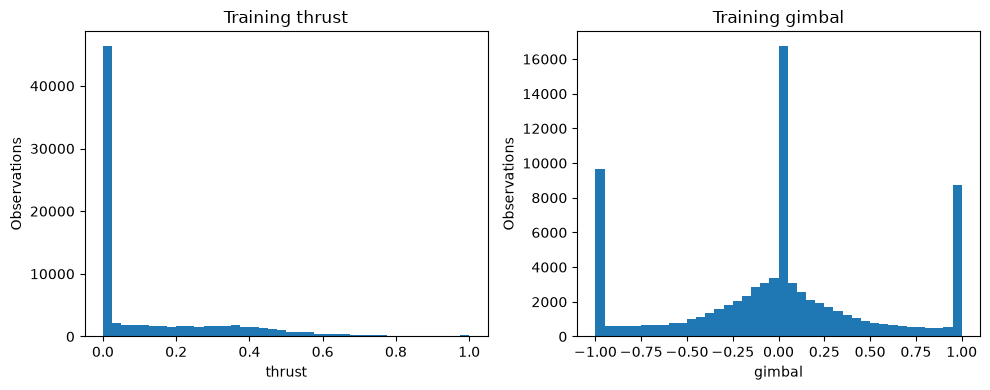

In [82]:
# These are continuous variables so we have to bin them first in order to plot a histogram.
# You can change the number of bins as you like, but 40 is a good starting point.
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, target in zip(axes, TARGETS):
    ax.hist(train[target], bins=40)
    ax.set(title=f"Training {target}", xlabel=target, ylabel="Observations")
plt.tight_layout()
plt.show()

## Prepare and train


In [83]:
# PyTorch models require tensors as input
# This is a helper function to convert the dataframes into tensors.
# It also splits the data into features and target variables.
def tensors(frame):
    # Make writable copies because torch.from_numpy shares the arrays' memory.
    x = frame[FEATURES].to_numpy(dtype=np.float32, copy=True)
    y = frame[TARGETS].to_numpy(dtype=np.float32, copy=True)
    return torch.from_numpy(x), torch.from_numpy(y)

# Making the splits and converting to tensors.
train_x, train_y = tensors(train)
val_x, val_y = tensors(val)
test_x, test_y = tensors(test)

# The model as is will only work with a batch size of at least 2.
# This is the case for any normalisation, as to compute the standard deviation you need at least two observations.
if batch_size < 2 or len(train_x) < 2:
    raise ValueError("Batch normalization needs at least two training observations per batch.")

# This is a PyTorch TensorDataset
# It takes the training data and creates a dataset that can be used by the DataLoader.
# It is essentially a wrapper around the training data that allows you to access it in a way that is compatible with PyTorch.
train_dataset = TensorDataset(train_x, train_y)

# This is a PyTorch DataLoader
# The idea is that it takes the training data and splits it into the specified batch size
# If you want it will also shuffle the data and drop the last batch if it is smaller than the specified batch size.
# It is an iterator so you can use it in a for loop to get the next batch of data.
# You might want to experiment with this.
loader = DataLoader(train_dataset, batch_size=min(batch_size, len(train_x)), shuffle=True, drop_last=True)

# Initialising your model from model.py (or any other model you have created)
model = create_model()
model.to(device)  # Move the model to the device (CPU or GPU or MPS for Apple Silicon))

# This is the optimizer
# As you have not covered optimizers/gradient descent or back prop yet, you can just use this as is.
# You can experiment with different learning rates instead.
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

# Feel free to change this, torch provides a number of default loss functions
# You can refer to the documentation to find more
# You can also implement your own loss function but be aware that it needs to be differentiable 
# and you will need to implement the backward pass yourself so I WOULD NOT RECOMMEND THIS FOR NOW.
loss_fn = nn.MSELoss()


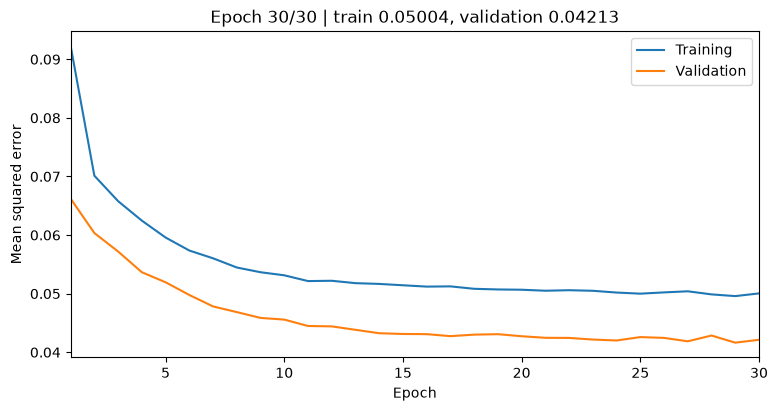

In [84]:
from IPython.display import DisplayHandle

# Keep the losses and refresh one plot after each epoch.
train_loss, val_loss = [], []
# You can also add metrics here 
# For example:
# mse_train, mse_val = [], []

fig, ax = plt.subplots(figsize=(8, 4))
train_curve, = ax.plot([], [], label="Training")
val_curve, = ax.plot([], [], label="Validation")
ax.set(xlabel="Epoch", ylabel="Mean squared error", xlim=(1, max(2, epochs)))
ax.legend()
fig.tight_layout()
loss_display = DisplayHandle()
loss_display.display(fig)
plt.close(fig)  # Prevent a second automatic plot at the end of the cell.

# We want to iterate through the dataset multiple times, each iteration is called an epoch.
for epoch in range(epochs):
    
    # This puts the model into training mode.
    # Basically it means that the model will update its weights
    model.train()
    
    # Init the loss for this epoch as 0 and the number of observations seen as 0
    total_loss = 0.0
    # total_mse = 0.0
    observations_seen = 0
    
    # This is where the loader as an iterator comes in.
    # The loader outputs two tensors at each iteration, one for the features and one for the targets
    # The shape of these is (batch_size, num_features) and (batch_size, num_targets) respectively.
    for x_batch, y_batch in loader:
        # We set the optimiser gradients to 0, by default they are accumulated with is usually undesirable.
        optimizer.zero_grad()
        
        # By default model() calls the model's forward() method.
        # So here the features are passed through the model to produce the predictions.
        predictions = model(x_batch)
        
        # We then compute loss between the predictions and the targets.
        loss = loss_fn(predictions, y_batch)
        
        # This is the backward propagation step where the gradients are computerd and the weights are updated.
        # You do not need to understand this yet. It will be covered soon.
        loss.backward()
        optimizer.step()
        
        # We then add the loss to the total for tracking.
        total_loss += loss.item() * len(x_batch)
        observations_seen += len(x_batch)
        
        # We can also compute metrics here, for example:
        # total_mse += mse(predictions, y_batch).item() * len(x_batch)
    
    # Append the training loss for this epoch
    train_loss.append(total_loss / observations_seen)
    # You can also add metrics here
    # For example:
    # mse_train.append(total_mse / observations_seen)
    
    # Swap the model to evaluation mode
    # This means that batch normalisation will not be updated and dropout will not be applied and the model will not update its weights.
    model.eval()
    with torch.no_grad():
        predictions = model(val_x)
        val_loss.append(loss_fn(predictions, val_y).item())
        # You can also add metrics here
        # For example:
        # mse_val.append(mse(predictions, val_y).item())

    # Update both curves and show the latest values in the plot title.
    epoch_numbers = range(1, len(train_loss) + 1)
    train_curve.set_data(epoch_numbers, train_loss)
    val_curve.set_data(epoch_numbers, val_loss)
    ax.relim()
    ax.autoscale_view(scalex=False)
    ax.set_title(f"Epoch {epoch + 1}/{epochs} | train {train_loss[-1]:.5f}, validation {val_loss[-1]:.5f}")
    loss_display.update(fig)

## Evaluate predictions

Use the held-out test flights for a final prediction check. These errors measure agreement with the expert commands. A low prediction error does not guarantee a safe landing; the next section tests the controller in the simulator.


thrust test MAE: 0.0262
gimbal test MAE: 0.1621


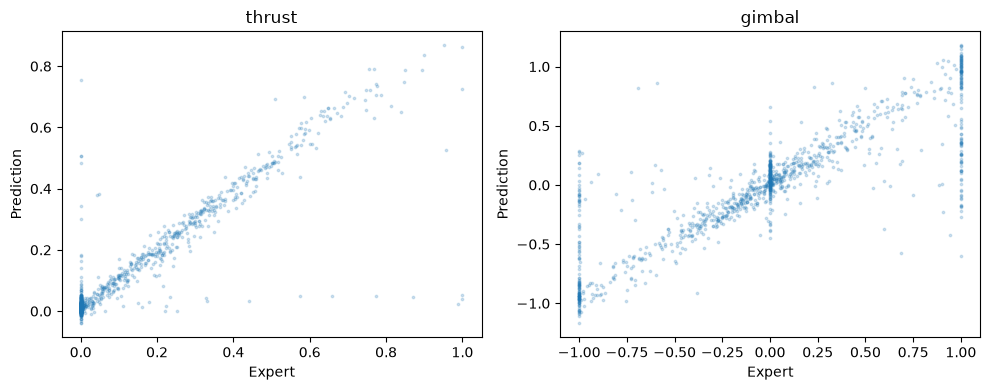

In [85]:
# Put the model into evaluation mode before using the test data.
# Batch normalisation now uses the running statistics from training
# and dropout, if you added it, is switched off.
# This does not turn off gradient tracking; that is what no_grad() below does.
model.eval()

# We only want predictions here, so there is no need to keep the information
# required for back propagation. This reduces the memory used during evaluation.
# test_x contains raw observations from flights that were held out of training.
# The model applies its own input normalisation, just as it will during a flight.
with torch.no_grad():
    # The output has shape (number_of_test_observations, 2).
    # The first column is thrust and the second column is gimbal.
    # .numpy() converts the CPU tensor into an array for NumPy and matplotlib.
    # If you move evaluation to a GPU, bring the tensors back with .cpu() first.
    predictions = model(test_x).numpy()

errors = np.abs(predictions - test_y.numpy())
for i, target in enumerate(TARGETS):
    print(f"{target} test MAE: {errors[:, i].mean():.4f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for i, (ax, target) in enumerate(zip(axes, TARGETS)):
    ax.scatter(test_y.numpy()[::10, i], predictions[::10, i], s=3, alpha=0.2)
    ax.set(xlabel="Expert", ylabel="Prediction", title=target)

plt.tight_layout()
plt.show()


## Simulate landings

Keep `rocket_closed_loop.py`, `rocket_runtime.py`, `rocket_physics.py`, `rocket_calibration.py`, `rocket_scoring.py` and `rocket_wind.py` in the notebook folder. The simulator needs NumPy; the expert and its SciPy dependencies are not needed.

The helper below runs the trained model on raw observations in evaluation mode. Complete the output activation functions in your model before training: thrust must be in `[0, 1]` and gimbal in `[-1, 1]`. Invalid commands raise an error rather than being silently clipped.

The public scenarios use the same physics and scoring rules as the online evaluator. Leaderboard scores use only held-out flights; these public starting scenarios are for local development.

To add a random starting position, uncomment `"random_start"` in `scenario_names`. It varies horizontal position from -40 to 40 m and centre-of-mass height from 350 to 850 m, keeping the demo flight's other initial conditions. Set `random_seed` to an integer to repeat a position, or `None` for a fresh one. You can also run `simulate(model, "random_start", seed=42)` directly.


In [86]:
from dataclasses import replace

from rocket_closed_loop import evaluate_closed_loop
from rocket_physics import Command
from rocket_runtime import scenario
from rocket_scoring import CONFIG


def simulate(model, scenario_name, *, seed=None):
    model.eval()

    # Find the device holding the model's parameters, for example CPU or CUDA.
    # Input tensors must be on the same device as the model that processes them.
    device = next(model.parameters()).device

    def policy(observation):
        with torch.inference_mode():
            # Convert the observations to the same floating-point type used in training.
            # unsqueeze(0) adds a batch dimension: (12,) becomes (1, 12).
            # Keep the observations raw because normalisation is already inside the model.
            x = torch.tensor(observation, dtype=torch.float32, device=device).unsqueeze(0)
            output = model(x)

        # Check the interface before interpreting the predictions as rocket controls.
        # For a batch of one observation we expect one row and exactly two outputs.
        if not isinstance(output, torch.Tensor) or tuple(output.shape) != (1, 2):
            raise ValueError("The model must return a tensor with shape (1, 2).")

        thrust, gimbal = output[0].tolist()
        return Command(thrust, gimbal)

    # Each scenario supplies a calibrated environment and a reproducible starting state.
    # initial_state contains values such as position, velocity, attitude and remaining fuel.
    if scenario_name == "random_start":
        # Randomise position only; keep the demo flight's velocity, attitude and fuel.
        scenario_name = "demo_descent"
        parameters, initial_state = scenario(scenario_name)
        rng = np.random.default_rng(seed)
        initial_state = replace(
            initial_state,
            x=float(rng.uniform(-40.0, 40.0)),
            y=float(rng.uniform(350.0, 850.0)),
        )
    else:
        parameters, initial_state = scenario(scenario_name)

    result = evaluate_closed_loop(
        policy, initial_state, parameters, scenario_name,
        control_mode="continuous",
    )

    if result["replay"]["status"] == "error":
        raise ValueError(result["termination_reason"])
    return result


In [87]:
# These are the four public starting scenarios used for local development.
# Keep all four public scenarios, or select a smaller list while experimenting.
# The online leaderboard uses only held-out flights, so these scores are not
# a guarantee of the score your submission will receive there.
scenario_names = [
    "demo_descent", "centred_descent", "crosswind_diagnostics", "near_ground_contact",
    # "random_start",  # Uncomment to add a flight from a random position.
]
random_seed = 42  # Use None for a fresh random position each time.


simulation_results = {name: simulate(model, name, seed=random_seed) for name in scenario_names}


summary = pd.DataFrame([
    {
        "Scenario": name,
        "Score / 100": result["scoring"]["score"],
        "Success": result["scoring"]["success"],
        "Simulation time (s)": result["replay"]["snapshots"][-1]["time"],
        "Landing feedback": "; ".join(result["scoring"]["reasons"]) or "Safe landing",
    }
    for name, result in simulation_results.items()
])


display(summary.round(2))
print(f"Mean score: {summary['Score / 100'].mean():.2f} / 100")
print(f"Landing success: {100 * summary['Success'].mean():.1f}%")


fig, axes = plt.subplots(1, len(simulation_results), figsize=(4 * len(simulation_results), 4), squeeze=False)


for ax, (name, result) in zip(axes.flat, simulation_results.items()):
    states = [frame["state"] for frame in result["replay"]["snapshots"]]
    ax.plot([state["x"] for state in states], [state["y"] for state in states], label="Flight path")
    ax.plot([CONFIG.pad_left, CONFIG.pad_right], [CONFIG.pad_height] * 2, color="black", linewidth=3, label="Landing pad")
    ax.set(title=name.replace("_", " "), xlabel="Horizontal position (m)", ylabel="Centre-of-mass height (m)")
    ax.legend()

# Leave enough room for the labels, then display all the flight paths together.
plt.tight_layout()
plt.show()


ValueError: Policy error (ValueError): command must be finite and normalized

### Optional: save a replay

Run this cell to save one flight, then choose **Import JSON** in the exercise page's public flight replay viewer to watch it. Change `replay_scenario` to another scenario you simulated.


In [ ]:
import json

# Choose one of the scenarios that we have already simulated.
# [0] selects the first name; you can replace it with another name from the list.
replay_scenario = scenario_names[0]

replay_path = Path(f"{replay_scenario}-replay.json")

replay_path.write_text(
    json.dumps(simulation_results[replay_scenario]["replay"], allow_nan=False),
    encoding="utf-8",
)
print(f"Saved {replay_path}. Import it into the exercise page's replay viewer.")


## Export weights and submit

Save only `weights.safetensors`. Your existing `model.py` source file already defines the architecture; there is no need to create another Python file.

The cell below checks that the current source file can load the trained state and reproduce a prediction, then saves the weights, including batch normalization parameters and running statistics. Upload that same source file as `model.py`, together with `weights.safetensors`, to **Submit a PyTorch model**. The form requires these exact filenames. Keep the source named `model.py`; no duplicate source file is needed.

If you change the architecture or output activations, retrain before exporting matching weights. If you trained from another module, update the `create_model` import near the top of this notebook.


In [ ]:
import inspect

# Keep the model in evaluation mode when comparing predictions.
model.eval()
model_path = Path(inspect.getsourcefile(create_model)).resolve()

state = {name: value.detach().cpu().contiguous() for name, value in model.state_dict().items()}

spec = importlib.util.spec_from_file_location("submission_model", model_path)
source_module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(source_module)

reloaded = source_module.create_model()
reloaded.load_state_dict(state, strict=True)
reloaded.eval()

with torch.inference_mode():
    sample = test_x[:1].to(next(model.parameters()).device)
    expected = model(sample)
    torch.testing.assert_close(reloaded(sample.cpu()), expected.cpu())

save_file(state, "weights.safetensors")

reloaded.load_state_dict(load_file("weights.safetensors"), strict=True)
with torch.inference_mode():
    torch.testing.assert_close(reloaded(sample.cpu()), expected.cpu())

# The upload form requires exactly model.py and weights.safetensors.
print(f"Saved weights.safetensors. Submit it with {model_path.name}, named model.py for upload.")
print("Example action (thrust, gimbal):", tuple(expected[0].cpu().tolist()))
